# Vigilancia del Virus del Nilo Occidental (WNV) en mosquitos de Chicago
### Proyecto 1P · Introducción a la Ciencia de Datos · PAO 2026-II · Paralelo 1

Integrantes: _(completar)_ · _(completar)_ · _(completar)_

---

## 1. Descripción del dataset

El dataset proviene del Portal de Datos Abiertos de la Ciudad de Chicago (*West Nile Virus (WNV) Mosquito Test Results*).
El Departamento de Salud Pública de Chicago (CDPH) coloca trampas de mosquitos cada semana durante la temporada (de mayo a octubre).
Los mosquitos capturados se agrupan en lotes de hasta 50 individuos de la misma especie y cada lote se analiza en laboratorio para detectar el virus.

Cada fila es un lote analizado (o una trampa-semana sin captura).

| Columna | Tipo | Descripción |
|---|---|---|
| SEASON YEAR | Temporal | Año de la temporada |
| WEEK | Temporal | Semana epidemiológica |
| WEEK_START / WEEK_END | Temporal | Inicio y fin de la semana |
| TEST ID | Identificador | ID del análisis de laboratorio |
| BLOCK | Espacial | Dirección (cuadra) de la trampa |
| TRAP | Categórico | Código de la trampa |
| TRAP_TYPE | Categórico | Tipo de trampa (GRAVID, CDC, SENTINEL…) |
| TEST DATE | Temporal | Fecha del análisis |
| NUMBER OF MOSQUITOES | Continuo | Mosquitos en el lote |
| RESULT | Categórico | `positive` / `negative` |
| SPECIES | Categórico | Especie de mosquito (género *Culex*) |
| COMMUNITY AREA NUMBER / NAME | Espacial | Una de las 77 áreas comunitarias de Chicago |
| WARD | Espacial | Distrito político/administrativo |
| ZIP CODE | Espacial | Código postal |
| LATITUDE / LONGITUDE / LOCATION | Espacial | Coordenadas de la trampa |

Fuente: [catalog.data.gov, West Nile Virus (WNV) Mosquito Test Results](https://catalog.data.gov/dataset/west-nile-virus-wnv-mosquito-test-results) (Ciudad de Chicago).

### Dataset 2: clima diario NOAA (GHCN-Daily)

Datos meteorológicos diarios de dos estaciones de la NOAA: O'Hare (noroeste de la ciudad) y Midway (suroeste), de 2007 a 2026. Se usan para explicar cuándo y dónde circula el virus, ya que la temperatura y la lluvia controlan la reproducción del mosquito y la replicación del virus.

| Columna | Tipo | Descripción |
|---|---|---|
| STATION / NAME | Categórico / Espacial | Estación meteorológica (O'Hare, Midway) |
| DATE | Temporal | Fecha |
| TMAX / TMIN / TAVG | Continuo | Temperatura máxima, mínima y media (°C) |
| PRCP | Continuo | Precipitación (mm) |
| SNOW | Continuo | Nieve (mm) |
| AWND | Continuo | Velocidad media del viento (m/s) |

Cada trampa se une a la estación más cercana y a la semana de captura, lo que permite relacionar el clima con la infección en tiempo y espacio.

Entre los dos datasets se cumplen los 4 tipos de datos requeridos: temporales (año, semana, fechas), categóricos (especie, resultado, trampa), continuos (número de mosquitos y métricas derivadas) y espaciales (área comunitaria, distrito, zip, lat/long).

## 2. Preguntas de negocio

El "negocio" aquí es la salud pública: el CDPH necesita decidir dónde y cuándo fumigar, dónde poner trampas y cuándo alertar a la población. Cada pregunta se responde combinando varias técnicas (métricas derivadas, medidas estadísticas, visualización).

Para leer las preguntas hacen falta tres medidas que se calculan en la sección 6:

- MIR (tasa mínima de infección): de cada 1000 mosquitos analizados, cuántos tenían el virus como mínimo. Se calcula como 1000 × lotes positivos / mosquitos analizados.
- Abundancia vectorial: mosquitos capturados en promedio por trampa y semana. Dice cuántos mosquitos hay, tengan virus o no.
- Trampa-semana: una trampa revisada durante una semana, haya capturado mosquitos o no.

Las preguntas van de las que se responden con conteos simples a las que necesitan más features: primero las que no usan ninguna feature creada por nosotros (P1), luego las que usan MIR o abundancia (P2 a P6), después las que usan positivos acumulados o MIR de semanas previas (P7 y P8) y al final las que usan el clima (P9 y P10).

| # | Pregunta | Cómo se responde |
|---|---|---|
| P1 | ¿Qué porcentaje de distritos concentra la mayoría de lotes positivos? (clasificación ABC) | Los distritos se ordenan de más a menos positivos y se acumula el porcentaje. Los que suman el 80 % son clase A, hasta el 95 % clase B y el resto clase C. Se compara en barras el % de distritos con el % de positivos de cada clase. |
| P2 | ¿En qué semanas de la temporada se concentra la infección y el pico se desplaza entre años? | Se grafica la MIR promedio de cada semana y se busca la semana con mayor MIR de cada año. |
| P3 | ¿Qué especie aporta más mosquitos y cuál se infecta más? | Por especie se calculan los mosquitos capturados por trampa-semana y la MIR, y se comparan en dos gráficos de barras. |
| P4 | ¿Los picos de abundancia y de infección ocurren en las mismas semanas? | Se dibujan juntas las curvas promedio de abundancia y MIR por semana. En cada año se busca la semana pico de cada una y se restan. |
| P5 | ¿Qué zonas de la ciudad tienen más infección? | Se calcula la MIR de cada zona en cada año y se compara la MIR mediana de las zonas en un gráfico de barras. |
| P6 | ¿Qué áreas comunitarias combinan mucha infección con muchos mosquitos y deberían tener prioridad de fumigación? | Cada área recibe su MIR y su abundancia. Se trazan las medianas de ambas y las áreas que superan las dos son las prioritarias. |
| P7 | ¿Los positivos acumulados hasta la semana 31 anticipan cuánto virus habrá en el resto de la temporada? | Por año se suman los lotes positivos hasta la semana 31 y, aparte, los que aparecen después. Se mide si los años con más positivos al inicio también tienen más al final. |
| P8 | ¿La MIR de las semanas previas anticipa la infección de la semana actual? | A cada semana se le añade la MIR de 1 a 4 semanas antes y se mide qué tan juntas suben y bajan. Se repite dentro de cada fase de la temporada para descartar que sea solo estacionalidad. |
| P9 | ¿Con cuántas semanas de anticipación la temperatura y la lluvia se asocian con la infección? | A cada semana se le añade la temperatura y la lluvia de 0 a 4 semanas antes, y se mide qué tan relacionadas están con la MIR. El resultado se muestra en una tabla de colores. |
| P10 | ¿Un enero más cálido anticipa una temporada más intensa? | Por año se obtiene la temperatura media de enero, la MIR anual y los positivos acumulados a la semana 31. Se mide si los años con enero más cálido tienen valores más altos. |


## 3. Librerías y configuración

In [1]:
!pip install numpy pandas matplotlib seaborn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 40)

RUTA_DATOS = 'export.csv'
RUTA_CLIMA = 'clima_noaa_chicago.csv'
RUTA_LIMPIO = 'wnv_limpio.csv'

### Carga de archivos en Google Colab
Si el notebook se ejecuta en Colab y los CSV no están en la sesión, la siguiente celda abre un diálogo para subirlos. Deben llamarse `export.csv` y `clima_noaa_chicago.csv`. Fuera de Colab basta con tener ambos archivos en la misma carpeta que el notebook.

In [3]:
import os
try:
    from google.colab import files   # solo existe dentro de Colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

faltan = [ruta for ruta in [RUTA_DATOS, RUTA_CLIMA] if not os.path.exists(ruta)]
if EN_COLAB and faltan:
    print('Sube los archivos:', faltan)
    subidos = files.upload()
    # Si Colab renombra el archivo (p. ej. 'export (1).csv'), lo renombramos al nombre esperado
    for nombre in subidos:
        for ruta in faltan:
            if nombre.split('.')[0].split(' ')[0] == ruta.split('.')[0] and nombre != ruta:
                os.rename(nombre, ruta)
print({ruta: os.path.exists(ruta) for ruta in [RUTA_DATOS, RUTA_CLIMA]})

{'export.csv': True, 'clima_noaa_chicago.csv': True}


## 4. Carga y exploración inicial

In [4]:
lotes_originales = pd.read_csv(RUTA_DATOS)
lotes_originales.columns = [columna.strip().replace('\\_', '_') for columna in lotes_originales.columns]
print('Filas:', f'{len(lotes_originales):,}', '| Columnas:', lotes_originales.shape[1])
lotes_originales.head()

Filas: 45,481 | Columnas: 19


,SEASON YEAR,WEEK,WEEK_START,WEEK_END,TEST ID,BLOCK,TRAP,TRAP_TYPE,TEST DATE,NUMBER OF MOSQUITOES,RESULT,SPECIES,COMMUNITY AREA NUMBER,COMMUNITY AREA NAME,WARD,ZIP CODE,LATITUDE,LONGITUDE,LOCATION
0,2026,39,09/27/2026,10/03/2026,60685.0,9XX W GARFIELD BLVD,T226,GRAVID,10/01/2026,2,negative,CULEX RESTUANS,61.0,NEW CITY,16.0,60609,-87.648925,41.794366,"(41.79436647814991, -87.64892513653469)"
1,2026,39,09/27/2026,10/03/2026,60637.0,51XX N MONT CLARE AVE,T223,GRAVID,10/01/2026,2,negative,CULEX PIPIENS,10.0,NORWOOD PARK,41.0,60656,-87.804589,41.974523,"(41.974522761157274, -87.80458946950488)"
2,2026,39,09/27/2026,10/03/2026,60690.0,108XX S HOMAN AVE,T245,GRAVID,10/01/2026,10,negative,CULEX PIPIENS,74.0,MOUNT GREENWOOD,19.0,60655,-87.705794,41.696316,"(41.69631550895749, -87.70579403580003)"
3,2026,39,09/27/2026,10/03/2026,60680.0,77XX S EBERHART AVE,T080,GRAVID,10/01/2026,1,negative,CULEX RESTUANS,69.0,GREATER GRAND CROSSING,6.0,60619,-87.612721,41.754148,"(41.75414841411549, -87.61272102258191)"
4,2026,39,09/27/2026,10/03/2026,60630.0,41XX N OAK PARK AVE,T002,GRAVID,10/01/2026,5,negative,CULEX PIPIENS,17.0,DUNNING,38.0,60634,-87.797517,41.956299,"(41.956298856118664, -87.79751744482932)"


In [5]:
lotes_originales.info()

<class 'pandas.DataFrame'>
RangeIndex: 45481 entries, 0 to 45480
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   SEASON YEAR            45481 non-null  int64  
 1   WEEK                   45481 non-null  int64  
 2   WEEK_START             45481 non-null  str    
 3   WEEK_END               45481 non-null  str    
 4   TEST ID                40108 non-null  float64
 5   BLOCK                  45481 non-null  str    
 6   TRAP                   45481 non-null  str    
 7   TRAP_TYPE              45481 non-null  str    
 8   TEST DATE              40108 non-null  str    
 9   NUMBER OF MOSQUITOES   45481 non-null  int64  
 10  RESULT                 40108 non-null  str    
 11  SPECIES                40108 non-null  str    
 12  COMMUNITY AREA NUMBER  45361 non-null  float64
 13  COMMUNITY AREA NAME    45361 non-null  str    
 14  WARD                   45361 non-null  float64
 15  ZIP CODE     

In [6]:
nulos = pd.DataFrame({'nulos': lotes_originales.isna().sum(),
                      '%': (lotes_originales.isna().mean()*100).round(2)})
nulos[nulos['nulos'] > 0]

,nulos,%
TEST ID,5373,11.81
TEST DATE,5373,11.81
RESULT,5373,11.81
SPECIES,5373,11.81
COMMUNITY AREA NUMBER,120,0.26
COMMUNITY AREA NAME,120,0.26
WARD,120,0.26
LATITUDE,120,0.26
LONGITUDE,120,0.26
LOCATION,120,0.26


In [7]:
for col in ['SEASON YEAR', 'TRAP_TYPE', 'RESULT', 'SPECIES']:
    print(f'--- {col} ---')
    print(lotes_originales[col].value_counts(dropna=False).sort_index().to_string(), '\n')

--- SEASON YEAR ---
SEASON YEAR
2007    4113
2008    2234
2009    2647
2010    2682
2011    2328
2012    2723
2013    2458
2014    2845
2015    2064
2016    2363
2017    1977
2018    2016
2019    2377
2020    2011
2021    1909
2022    1443
2023    1520
2024    1527
2025    2104
2026    2140 

--- TRAP_TYPE ---
TRAP_TYPE
CDC          1369
GRAVID      43698
MAGNETIC        1
OVI            12
SENTINEL      401 

--- RESULT ---
RESULT
negative    36166
positive     3942
NaN          5373 

--- SPECIES ---
SPECIES
CULEX ERRATICUS              43
CULEX PIPIENS              6905
CULEX PIPIENS/RESTUANS    18043
CULEX RESTUANS            13761
CULEX SALINARIUS            245
CULEX TARSALIS               82
CULEX TERRITANS            1006
UNSPECIFIED CULEX            23
NaN                        5373 



In [8]:
lotes_originales['NUMBER OF MOSQUITOES'].describe()

count    45481.000000
mean        11.307139
std         15.012672
min          0.000000
25%          1.000000
50%          4.000000
75%         15.000000
max         77.000000
Name: NUMBER OF MOSQUITOES, dtype: float64

## 5. Limpieza y transformación

Pasos:

1. Se eliminan los duplicados exactos.
2. Si un TEST ID aparece dos veces (el mismo análisis registrado dos veces), se conserva uno.
3. Los registros sin análisis (sin `RESULT`, `SPECIES` o `TEST DATE`) son trampa-semanas sin captura (0 mosquitos). No sirven para medir infección, pero sí para medir abundancia, porque una trampa revisada que capturó 0 también cuenta como trampa-semana. Se separan en `trampas_sin_captura` y no entran al análisis de infección.
4. Los lotes con 0 mosquitos o menos pero con resultado son inconsistentes y se eliminan.
5. Se convierten las fechas de texto a `datetime`.
6. Coordenadas: en este export las columnas `LATITUDE` y `LONGITUDE` vienen intercambiadas (la "latitud" vale unos -87). Se corrigen y, si faltan, se recuperan desde `LOCATION`. Se eliminan las coordenadas fuera del rectángulo de Chicago.
7. Si la fecha de análisis cae a más de 14 días de la semana de captura, se trata como un error de registro y se elimina.
8. Tipo de trampa: cerca del 96 % son trampas GRAVID. Las CDC, SENTINEL y OVI capturan con otra eficiencia y harían incomparable la abundancia, así que se excluyen.
9. Las especies poco frecuentes (menos del 1 % de los lotes) se agrupan en `OTRAS`.

El porcentaje de ruido es la proporción de registros que no sirven para el análisis de infección sobre el total.

In [9]:
lotes = lotes_originales.copy()
filas_originales = len(lotes)
ruido = {}

antes = len(lotes)
lotes = lotes.drop_duplicates()
ruido['1. Duplicados exactos'] = antes - len(lotes)

# Paso 2: TEST ID duplicado (solo entre filas que tienen TEST ID)
antes = len(lotes)
con_id = lotes['TEST ID'].notna()
lotes = pd.concat([lotes[con_id].drop_duplicates(subset='TEST ID'), lotes[~con_id]])
ruido['2. TEST ID duplicado'] = antes - len(lotes)

sin_test = lotes['RESULT'].isna() | lotes['SPECIES'].isna() | lotes['TEST DATE'].isna()
trampas_sin_captura = lotes[sin_test].copy()
ruido['3. Sin análisis (trampa sin captura)'] = int(sin_test.sum())
lotes = lotes[~sin_test].copy()

antes = len(lotes)
lotes = lotes[lotes['NUMBER OF MOSQUITOES'] > 0]
ruido['4. Lote con 0 mosquitos'] = antes - len(lotes)
pd.Series(ruido)

1. Duplicados exactos                      0
2. TEST ID duplicado                       0
3. Sin análisis (trampa sin captura)    5373
4. Lote con 0 mosquitos                    0
dtype: int64

In [10]:
for columna in ['WEEK_START', 'WEEK_END', 'TEST DATE']:
    lotes[columna] = pd.to_datetime(lotes[columna], format='mixed', errors='coerce')
    trampas_sin_captura[columna] = pd.to_datetime(trampas_sin_captura[columna], format='mixed', errors='coerce')
mala_fecha = lotes['TEST DATE'].isna()
ruido['5. Fecha no convertible'] = int(mala_fecha.sum())
lotes = lotes[~mala_fecha]

def corregir_coordenadas(datos):
    datos = datos.copy()
    lat, lon = datos['LATITUDE'].copy(), datos['LONGITUDE'].copy()
    # Si la "latitud" es negativa, las columnas están intercambiadas
    intercambiadas = lat < 0
    datos.loc[intercambiadas, 'LATITUDE'], datos.loc[intercambiadas, 'LONGITUDE'] = lon[intercambiadas], lat[intercambiadas]
    coord_location = datos['LOCATION'].astype(str).str.extract(r'\(([-\d.]+),\s*([-\d.]+)\)').astype(float)
    datos['LATITUDE'] = datos['LATITUDE'].fillna(coord_location[0])
    datos['LONGITUDE'] = datos['LONGITUDE'].fillna(coord_location[1])
    return datos, int(intercambiadas.sum())

lotes, cantidad_intercambiadas = corregir_coordenadas(lotes)
trampas_sin_captura, _ = corregir_coordenadas(trampas_sin_captura)
print(f'Filas con lat/long intercambiadas y corregidas: {cantidad_intercambiadas:,}')

dentro_de_chicago = lotes['LATITUDE'].between(41.60, 42.05) & lotes['LONGITUDE'].between(-87.95, -87.50)
ruido['6. Coordenadas fuera de Chicago / faltantes'] = int((~dentro_de_chicago).sum())
lotes = lotes[dentro_de_chicago]

Filas con lat/long intercambiadas y corregidas: 40,077


In [11]:
dias_desfase = (lotes['TEST DATE'] - lotes['WEEK_START']).dt.days
fecha_en_rango = dias_desfase.between(-14, 21) | lotes['WEEK_START'].isna()
ruido['7. Fecha de análisis fuera de rango'] = int((~fecha_en_rango).sum())
lotes = lotes[fecha_en_rango]

# Paso 8: tipo de trampa. Solo GRAVID es comparable entre años (otras trampas capturan distinto)
no_gravid = lotes['TRAP_TYPE'] != 'GRAVID'
ruido['8. Trampa no GRAVID (no comparable)'] = int(no_gravid.sum())
lotes = lotes[~no_gravid]
trampas_sin_captura = trampas_sin_captura[trampas_sin_captura['TRAP_TYPE'] == 'GRAVID']

frecuencia = lotes['SPECIES'].value_counts(normalize=True)
especies_raras = frecuencia[frecuencia < 0.01].index
lotes['ESPECIE'] = lotes['SPECIES'].where(~lotes['SPECIES'].isin(especies_raras), 'OTRAS')
lotes['ESPECIE'] = lotes['ESPECIE'].str.replace('CULEX ', 'Cx. ').str.title().str.replace('Cx. ', 'Cx. ')
print('Especies agrupadas en OTRAS:', list(especies_raras))

Especies agrupadas en OTRAS: ['CULEX SALINARIUS', 'CULEX TARSALIS', 'CULEX ERRATICUS', 'UNSPECIFIED CULEX']


In [12]:
tabla_ruido = pd.DataFrame({'filas': pd.Series(ruido)})
tabla_ruido['% del total'] = (tabla_ruido['filas'] / filas_originales * 100).round(2)
total_ruido = tabla_ruido['filas'].sum()
display(tabla_ruido)
print(f'Total original: {filas_originales:,} | Útiles para análisis de infección: {len(lotes):,}')
print(f'PORCENTAJE DE RUIDO: {total_ruido/filas_originales*100:.2f} %')

,filas,% del total
1. Duplicados exactos,0,0.00
2. TEST ID duplicado,0,0.00
3. Sin análisis (trampa sin captura),5373,11.81
4. Lote con 0 mosquitos,0,0.00
5. Fecha no convertible,0,0.00
6. Coordenadas fuera de Chicago / faltantes,31,0.07
7. Fecha de análisis fuera de rango,351,0.77
8. Trampa no GRAVID (no comparable),1501,3.30


Total original: 45,481 | Útiles para análisis de infección: 38,225
PORCENTAJE DE RUIDO: 15.95 %


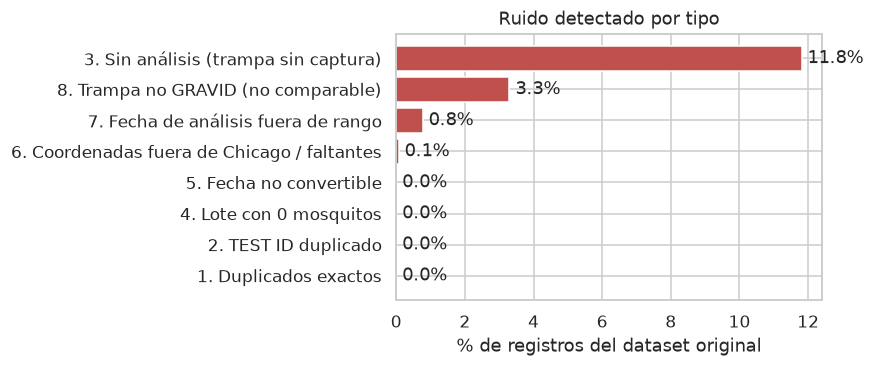

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ordenado = tabla_ruido.sort_values('% del total')
ax.barh(ordenado.index, ordenado['% del total'], color='#c0504d')
ax.set_xlabel('% de registros del dataset original')
ax.set_title('Ruido detectado por tipo')
for posicion, valor in enumerate(ordenado['% del total']): ax.text(valor, posicion, f' {valor:.1f}%', va='center')
plt.tight_layout()
plt.show()

## 5b. Dataset 2: clima NOAA, carga, limpieza y transformación

Pasos:
1. Se verifican los duplicados (estación y fecha).
2. TAVG viene 100 % vacía, así que se reconstruye como (TMAX + TMIN) / 2.
3. SNOW no aplica a la temporada de mosquitos (de mayo a octubre) y en Midway está casi vacía, así que se descarta.
4. Los días sin PRCP o AWND se marcan, y la lluvia faltante se excluye de las sumas semanales.
5. Se convierten las fechas y se agrupa por la semana epidemiológica del dataset de mosquitos (semanas de domingo a sábado).

In [14]:
clima_raw = pd.read_csv(RUTA_CLIMA)
print('Filas:', f'{len(clima_raw):,}')
display(clima_raw.head())
nulos_clima = pd.DataFrame({'nulos %': (clima_raw.isna().mean()*100).round(2)})
display(nulos_clima.T)
display(clima_raw.groupby('NAME').agg(desde=('DATE','min'), hasta=('DATE','max'), dias=('DATE','size'),
                                      snow_nulos=('SNOW', lambda x: round(x.isna().mean()*100,1))))

Filas: 14,512


,STATION,NAME,DATE,AWND,PRCP,SNOW,TAVG,TMAX,TMIN
0,USW00094846,"CHICAGO OHARE INTERNATIONAL AIRPORT, IL US",2007-01-01,5.9,0.0,0.0,NaN,6.1,-1.7
1,USW00094846,"CHICAGO OHARE INTERNATIONAL AIRPORT, IL US",2007-01-02,4.3,0.0,0.0,NaN,6.1,-3.3
2,USW00094846,"CHICAGO OHARE INTERNATIONAL AIRPORT, IL US",2007-01-03,7.0,0.0,0.0,NaN,8.9,0.6
3,USW00094846,"CHICAGO OHARE INTERNATIONAL AIRPORT, IL US",2007-01-04,7.8,16.8,0.0,NaN,11.1,3.9
4,USW00094846,"CHICAGO OHARE INTERNATIONAL AIRPORT, IL US",2007-01-05,3.6,0.8,0.0,NaN,10.0,5.6


,STATION,NAME,DATE,AWND,PRCP,SNOW,TAVG,TMAX,TMIN
nulos %,0.0,0.0,0.0,0.05,0.08,48.56,100.0,0.0,0.0


,desde,hasta,dias,snow_nulos
NAME,,,,
"CHICAGO MIDWAY AIRPORT, IL US",2007-01-01,2026-11-13,7255,97.1
"CHICAGO OHARE INTERNATIONAL AIRPORT, IL US",2007-01-01,2026-11-13,7257,0.0


In [15]:
clima = clima_raw.copy()
filas_clima = len(clima)
ruido_clima = {}

antes = len(clima)
clima = clima.drop_duplicates(['STATION','DATE'])
ruido_clima['Duplicados estación-fecha'] = antes - len(clima)

clima['TAVG'] = (clima['TMAX'] + clima['TMIN']) / 2

clima = clima.drop(columns=['SNOW'])

ruido_clima['Días sin PRCP'] = int(clima['PRCP'].isna().sum())
ruido_clima['Días sin AWND'] = int(clima['AWND'].isna().sum())

clima['DATE'] = pd.to_datetime(clima['DATE'])
clima['ESTACION'] = np.where(clima['NAME'].str.contains('OHARE'), "O'Hare", 'Midway')
# inicio de semana (domingo), igual que WEEK_START en el dataset de mosquitos
clima['WEEK_START'] = clima['DATE'] - pd.to_timedelta((clima['DATE'].dt.weekday + 1) % 7, unit='D')

celdas_nulas = clima_raw[['AWND','PRCP','TMAX','TMIN']].isna().sum().sum()
print('Ruido en clima:', ruido_clima)
print(f'Celdas útiles faltantes (AWND, PRCP, TMAX, TMIN): {celdas_nulas} de {filas_clima*4:,} '
      f'= {celdas_nulas/(filas_clima*4)*100:.2f} %  |  columnas descartadas: TAVG original (100 % vacía), SNOW')

Ruido en clima: {'Duplicados estación-fecha': 0, 'Días sin PRCP': 11, 'Días sin AWND': 7}
Celdas útiles faltantes (AWND, PRCP, TMAX, TMIN): 18 de 58,048 = 0.03 %  |  columnas descartadas: TAVG original (100 % vacía), SNOW


### Agregación semanal del clima

La temperatura semanal es el promedio de las siete medias diarias y la lluvia semanal es la suma de los siete días, igual que en Karki et al. (2020). Con estas series se construyen las features climáticas de la sección 6.

In [16]:
clima['AÑO'] = clima['DATE'].dt.year
clima_semanal = (clima.groupby(['ESTACION', 'WEEK_START'])
             .agg(TAVG_SEM=('TAVG', 'mean'), PRCP_SEM=('PRCP', 'sum'))
             .reset_index()
             .sort_values(['ESTACION', 'WEEK_START']))
clima_semanal.head()

,ESTACION,WEEK_START,TAVG_SEM,PRCP_SEM
0,Midway,2006-12-31,5.708333,37.4
1,Midway,2007-01-07,2.492857,2.3
2,Midway,2007-01-14,-3.142857,16.5
3,Midway,2007-01-21,-1.300000,1.0
4,Midway,2007-01-28,-10.342857,0.0


In [17]:
COORD_ESTACIONES = {"O'Hare": (41.9950, -87.9336), 'Midway': (41.7861, -87.7522)}
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))
distancias_km = pd.DataFrame({e: haversine(lotes['LATITUDE'], lotes['LONGITUDE'], la, lo) for e, (la, lo) in COORD_ESTACIONES.items()})
lotes['ESTACION'] = distancias_km.idxmin(axis=1).values
lotes['DIST_ESTACION_KM'] = distancias_km.min(axis=1).values
print('Lotes por estación:', lotes['ESTACION'].value_counts().to_dict())

Lotes por estación: {'Midway': 25123, "O'Hare": 13102}


## 6. Ingeniería de características (nuevas métricas)

Siete métricas que no existen en el dataset original. Cada una sigue la definición de una guía o un estudio publicado sobre vigilancia del virus; Karki et al. (2020) y Ruiz et al. (2010) trabajaron con datos de Chicago.

| # | Feature | Definición | Referencia |
|---|---|---|---|
| 1 | `MIR` | Tasa mínima de infección: 1000 × lotes positivos / mosquitos analizados. Supone un solo mosquito infectado por lote positivo, así que subestima la infección cuando esta es alta | CDC (2013), pp. 17-18; Karki et al. (2020) |
| 2 | `MIR_PREV_1` … `MIR_PREV_4` | MIR de 1, 2, 3 y 4 semanas antes. En Chicago, la MIR de semanas previas aumentó la probabilidad de casos humanos; la correlación más fuerte fue a una semana | Karki et al. (2020) |
| 3 | `POS_ACUM` | Lotes positivos acumulados en la temporada hasta cada semana. Los acumulados a la semana 31 explicaron el 93 % de la variación de los casos humanos anuales | Karki et al. (2020) |
| 4 | `ABUNDANCIA` | Abundancia vectorial: mosquitos capturados / trampa-semanas, incluidas las trampas revisadas con 0 capturas | CDC (2013), p. 17; metadatos del portal de Chicago |
| 5 | `TEMP_PREV_1` … `TEMP_PREV_4` | Temperatura media semanal de 1 a 4 semanas antes | Karki et al. (2020); Ruiz et al. (2010) |
| 6 | `LLUVIA_PREV_1` … `LLUVIA_PREV_4` | Lluvia semanal (mm) de 1 a 4 semanas antes | Karki et al. (2020); Ruiz et al. (2010) |
| 7 | `TEMP_ENERO` | Invierno cálido: temperatura media de enero del año de la temporada | Karki et al. (2020) |

El CDC define la abundancia por noche de trampa. Aquí cada trampa se revisa una vez por semana (el 99,6 % de las trampa-semanas tiene una sola fecha de recolección), así que se usa la trampa-semana como aproximación.

También se crean variables auxiliares para agrupar los análisis: `POSITIVO`, `AÑO`, `MES`, `FASE` de la temporada, `RANGO_LOTE` y `ZONA` de la ciudad.

Referencias
- Centers for Disease Control and Prevention (2013). *West Nile Virus in the United States: Guidelines for Surveillance, Prevention, and Control* (4th revision). https://stacks.cdc.gov/view/cdc/22064
- Karki, S., Brown, W. M., Uelmen, J., Ruiz, M. O., & Smith, R. L. (2020). The drivers of West Nile virus human illness in the Chicago, Illinois, USA area: Fine scale dynamic effects of weather, mosquito infection, social, and biological conditions. *PLoS ONE*, 15(5), e0227160. https://pmc.ncbi.nlm.nih.gov/articles/PMC7241786
- Ruiz, M. O., Chaves, L. F., Hamer, G. L., Sun, T., Brown, W. M., Walker, E. D., Haramis, L., Goldberg, T. L., & Kitron, U. D. (2010). Local impact of temperature and precipitation on West Nile virus infection in *Culex* species mosquitoes in northeast Illinois, USA. *Parasites & Vectors*, 3, 19. https://pmc.ncbi.nlm.nih.gov/articles/PMC2856545
- City of Chicago (2024). *West Nile Virus (WNV) Mosquito Test Results*, metadatos del dataset. https://data.cityofchicago.org/d/jqe8-8r6s
- Wikipedia (2026). *Community areas in Chicago* (agrupación de las 77 áreas en 9 sectores, no oficial). https://en.wikipedia.org/wiki/Community_areas_in_Chicago

### Qué significa cada feature

Los ejemplos usan la semana 33 de 2025 (10 al 16 de agosto), la de mayor infección de toda la serie.

| Término | Qué significa | Ejemplo |
|---|---|---|
| Lote | Grupo de hasta 50 mosquitos de la misma especie y trampa que el laboratorio analiza junto. Sale positivo si al menos uno tiene el virus | Una trampa con 120 mosquitos de una especie se analiza en 3 lotes |
| Vector | Mosquito que puede transmitir el virus. En Chicago son las especies *Culex* | |
| Semana epidemiológica | Número de semana del año que usa el CDC, de domingo a sábado | La semana 31 cae a fines de julio o inicios de agosto |
| Trampa-semana | Una trampa revisada en una semana. Cuenta aunque no haya capturado nada | 27.159 trampa-semanas en total; 5.219 sin mosquitos |
| `MIR` | De cada 1000 mosquitos analizados, cuántos tenían el virus como mínimo. Es "mínima" porque un lote positivo puede tener dos o más mosquitos infectados y se cuenta como uno | 42,1: al menos 42 de cada 1000 mosquitos estaban infectados. En toda la serie el valor es 8,1 |
| `ABUNDANCIA` | Cuántos mosquitos caen en promedio en una trampa en una semana. Dice cuántos mosquitos hay, sin importar si tienen virus | 22 mosquitos por trampa-semana. En todo 2022 fueron 8 y en 2012, 26 |
| Rezago | Cuántas semanas hacia atrás se mira. El sufijo `_PREV_k` indica un rezago de k semanas | `TEMP_PREV_3` de la semana 33 es la temperatura de la semana 30 |
| `MIR_PREV_k` | La MIR de k semanas antes, puesta junto a la semana actual para ver si lo de antes anticipa lo de ahora | `MIR_PREV_1` = 35,5, la MIR de la semana 32 |
| `POS_ACUM` | Contador de lotes positivos desde el inicio de la temporada. Nunca baja y vuelve a cero cada año | 327 positivos acumulados. En 2012 ya había 336 en la semana 31 |
| `TEMP_PREV_k` | Temperatura media de la semana de hace k semanas. El calor actúa con retraso porque el mosquito tarda en crecer y el virus tarda en multiplicarse dentro de él | `TEMP_PREV_3` = 25,9 °C |
| `LLUVIA_PREV_k` | Lluvia total (mm) de la semana de hace k semanas. 1 mm equivale a 1 litro por metro cuadrado | `LLUVIA_PREV_1` = 0 mm: la semana anterior no llovió |
| `TEMP_ENERO` | Temperatura media de enero. Ruiz et al. (2010) proponen que con un invierno suave podrían sobrevivir más mosquitos adultos hasta la primavera | Enero de 2012: −0,8 °C; enero de 2014: −8,6 °C |

In [18]:
lotes['POSITIVO'] = (lotes['RESULT'].str.lower() == 'positive').astype(int)
lotes['AÑO'] = lotes['SEASON YEAR'].astype(int)
lotes['MES'] = lotes['TEST DATE'].dt.month
LIMITES_FASE = [0, 28, 35, 60]
NOMBRES_FASE = ['Temprana (semanas ≤28)', 'Pico (semanas 29-35)', 'Tardía (semanas ≥36)']
lotes['FASE'] = pd.cut(lotes['WEEK'], LIMITES_FASE, labels=NOMBRES_FASE)
lotes['RANGO_LOTE'] = pd.cut(lotes['NUMBER OF MOSQUITOES'], [0, 5, 15, 30, 1000],
                          labels=['1-5', '6-15', '16-30', '31+'])

# 9 sectores de Chicago (agrupación no oficial) según https://en.wikipedia.org/wiki/Community_areas_in_Chicago
ZONAS = {
    'Extremo norte':    [1,2,3,4,9,10,11,12,13,14,76,77],
    'Noroeste':         [15,16,17,18,19,20],
    'Norte':            [5,6,7,21,22],
    'Centro':           [8,32,33],
    'Oeste':            [23,24,25,26,27,28,29,30,31],
    'Sur':              [34,35,36,37,38,39,40,41,42,43,60,68,69],
    'Suroeste':         [56,57,58,59,61,62,63,64,65,66,67],
    'Extremo sureste':  [44,45,46,47,48,49,50,51,52,53,54,55],
    'Extremo suroeste': [70,71,72,73,74,75],
}
mapa_zona = {area: zona for zona, areas in ZONAS.items() for area in areas}
ORDEN_ZONAS = list(ZONAS.keys())
lotes['ZONA'] = lotes['COMMUNITY AREA NUMBER'].map(mapa_zona)
trampas_sin_captura['ZONA'] = trampas_sin_captura['COMMUNITY AREA NUMBER'].map(mapa_zona)
lotes[['AÑO','WEEK','ESPECIE','NUMBER OF MOSQUITOES','POSITIVO','FASE','RANGO_LOTE','ZONA']].head()

,AÑO,WEEK,ESPECIE,NUMBER OF MOSQUITOES,POSITIVO,FASE,RANGO_LOTE,ZONA
0,2026,39,Cx. Restuans,2,0,Tardía (semanas ≥36),1-5,Suroeste
1,2026,39,Cx. Pipiens,2,0,Tardía (semanas ≥36),1-5,Extremo norte
2,2026,39,Cx. Pipiens,10,0,Tardía (semanas ≥36),6-15,Extremo suroeste
3,2026,39,Cx. Restuans,1,0,Tardía (semanas ≥36),1-5,Sur
4,2026,39,Cx. Pipiens,5,0,Tardía (semanas ≥36),1-5,Noroeste


### Features climáticas: temperatura y lluvia de semanas previas, invierno cálido

Se calculan sobre la serie semanal completa de cada estación antes de unirlas a los lotes. Así el rezago de una semana es siempre la semana calendario anterior, aunque esa semana no haya tenido muestreo.

In [19]:
REZAGOS = range(1, 5)
for rezago in REZAGOS:
    clima_semanal[f'TEMP_PREV_{rezago}'] = clima_semanal.groupby('ESTACION')['TAVG_SEM'].shift(rezago)
    clima_semanal[f'LLUVIA_PREV_{rezago}'] = clima_semanal.groupby('ESTACION')['PRCP_SEM'].shift(rezago)

temp_enero = (clima[clima['DATE'].dt.month == 1]
              .groupby(['ESTACION', 'AÑO'])['TAVG'].mean()
              .rename('TEMP_ENERO').reset_index())

lotes = (lotes.merge(clima_semanal, on=['ESTACION', 'WEEK_START'], how='left')
        .merge(temp_enero, on=['ESTACION', 'AÑO'], how='left'))
print(f"Lotes sin clima asociado: {lotes['TEMP_PREV_1'].isna().sum()}")

clima_ciudad = clima_semanal.drop(columns='ESTACION').groupby('WEEK_START').mean().reset_index()
temp_enero_ciudad = temp_enero.groupby('AÑO')['TEMP_ENERO'].mean()
lotes[['WEEK_START', 'ESTACION', 'TAVG_SEM', 'TEMP_PREV_1', 'LLUVIA_PREV_1', 'TEMP_ENERO']].head()

Lotes sin clima asociado: 0


,WEEK_START,ESTACION,TAVG_SEM,TEMP_PREV_1,LLUVIA_PREV_1,TEMP_ENERO
0,2026-09-27,Midway,17.135714,16.828571,38.6,-5.003226
1,2026-09-27,O'Hare,16.942857,16.878571,30.7,-5.612903
2,2026-09-27,Midway,17.135714,16.828571,38.6,-5.003226
3,2026-09-27,Midway,17.135714,16.828571,38.6,-5.003226
4,2026-09-27,O'Hare,16.942857,16.878571,30.7,-5.612903


### Features de vigilancia: MIR, abundancia vectorial, MIR de semanas previas y positivos acumulados

In [20]:
def resumen_infeccion(grupo):
    return pd.Series({
        'lotes': len(grupo),
        'positivos': grupo['POSITIVO'].sum(),
        'mosquitos': grupo['NUMBER OF MOSQUITOES'].sum(),
        'MIR': grupo['POSITIVO'].sum() / grupo['NUMBER OF MOSQUITOES'].sum() * 1000,
    })

# Trampa-semanas: combinaciones únicas trampa-semana, incluidas las trampas revisadas sin captura
COLUMNAS_TRAMPA_SEMANA = ['AÑO', 'WEEK', 'TRAP', 'COMMUNITY AREA NUMBER', 'ZONA', 'WARD']
trampa_semanas_unicas = pd.concat([lotes[COLUMNAS_TRAMPA_SEMANA],
                trampas_sin_captura.assign(AÑO=trampas_sin_captura['SEASON YEAR'].astype(int))[COLUMNAS_TRAMPA_SEMANA]]
              ).drop_duplicates(['AÑO', 'WEEK', 'TRAP'])

def abundancia(keys):
    trampa_semanas = trampa_semanas_unicas.groupby(keys).size().rename('trampa_semanas')
    mosquitos = lotes.groupby(keys)['NUMBER OF MOSQUITOES'].sum().rename('mosq_capturados')
    out = pd.concat([trampa_semanas, mosquitos], axis=1).fillna({'mosq_capturados': 0})
    out['ABUNDANCIA'] = out['mosq_capturados'] / out['trampa_semanas']
    return out[['trampa_semanas', 'ABUNDANCIA']]

def metricas(keys):
    return lotes.groupby(keys).apply(resumen_infeccion).join(abundancia(keys), how='outer')

print(f'Trampa-semanas: {len(trampa_semanas_unicas):,} (de ellas sin captura: {len(trampas_sin_captura):,})')
resumen_infeccion(lotes).round(3)

Trampa-semanas: 27,159 (de ellas sin captura: 5,219)


lotes         38225.000
positivos      3800.000
mosquitos    469570.000
MIR               8.093
dtype: float64

In [21]:
MIN_MOSQUITOS_SEMANA = 100   # con menos mosquitos por semana la MIR salta entre 0 y valores extremos

metricas_semanales = metricas(['AÑO', 'WEEK']).reset_index().sort_values(['AÑO', 'WEEK'])
metricas_semanales['POS_ACUM'] = metricas_semanales.groupby('AÑO')['positivos'].cumsum()

# Se une por número de semana, no por posición, para no confundir semanas sin muestreo
for rezago in REZAGOS:
    previa = metricas_semanales[['AÑO', 'WEEK', 'MIR']].assign(WEEK=metricas_semanales['WEEK'] + rezago).rename(columns={'MIR': f'MIR_PREV_{rezago}'})
    metricas_semanales = metricas_semanales.merge(previa, on=['AÑO', 'WEEK'], how='left')

inicio_semana = lotes.groupby(['AÑO', 'WEEK'])['WEEK_START'].min().reset_index()
metricas_semanales = (metricas_semanales
                      .merge(inicio_semana, on=['AÑO', 'WEEK'], how='left')
                      .merge(clima_ciudad, on='WEEK_START', how='left'))
metricas_semanales['TEMP_ENERO'] = metricas_semanales['AÑO'].map(temp_enero_ciudad)
metricas_semanales['FASE'] = pd.cut(metricas_semanales['WEEK'], LIMITES_FASE, labels=NOMBRES_FASE)
semanas_validas = metricas_semanales[metricas_semanales['mosquitos'] >= MIN_MOSQUITOS_SEMANA]
print(f'Semanas: {len(metricas_semanales)} | con al menos {MIN_MOSQUITOS_SEMANA} mosquitos: {len(semanas_validas)}')
metricas_semanales[['AÑO','WEEK','lotes','mosquitos','MIR','MIR_PREV_1','POS_ACUM','ABUNDANCIA','TAVG_SEM','TEMP_PREV_1','LLUVIA_PREV_1']].head()

Semanas: 367 | con al menos 100 mosquitos: 348


,AÑO,WEEK,lotes,mosquitos,MIR,MIR_PREV_1,POS_ACUM,ABUNDANCIA,TAVG_SEM,TEMP_PREV_1,LLUVIA_PREV_1
0,2007,21,20.0,31.0,0.0,NaN,0.0,0.563636,19.039286,16.296429,15.15
1,2007,22,48.0,100.0,0.0,0.0,0.0,1.724138,22.378571,19.039286,20.10
2,2007,23,NaN,NaN,NaN,0.0,NaN,0.000000,NaN,NaN,NaN
3,2007,24,54.0,132.0,0.0,NaN,0.0,2.357143,23.989286,19.389286,22.05
4,2007,25,52.0,142.0,0.0,0.0,0.0,2.491228,22.742857,23.989286,0.00


## 7. Analítica descriptiva y estadística general

In [22]:
anual = lotes.groupby('AÑO').apply(resumen_infeccion)
anual = anual.join(abundancia(['AÑO']))
anual['trampas_activas'] = trampa_semanas_unicas.groupby('AÑO')['TRAP'].nunique()
anual['TEMP_ENERO'] = temp_enero_ciudad
anual.round(2)

,lotes,positivos,mosquitos,MIR,trampa_semanas,ABUNDANCIA,trampas_activas,TEMP_ENERO
AÑO,,,,,,,,
2007,2350.0,150.0,22181.0,6.76,1422,15.60,98,-1.42
2008,2073.0,99.0,23800.0,4.16,1115,21.35,86,-4.42
2009,2193.0,19.0,20283.0,0.94,1462,13.87,86,-8.29
2010,2357.0,74.0,21747.0,3.40,1371,15.86,97,-5.35
2011,2051.0,57.0,18790.0,3.03,1358,13.84,90,-5.83
2012,2478.0,437.0,36021.0,12.13,1376,26.18,90,-0.78
2013,2381.0,239.0,36321.0,6.58,1365,26.61,87,-2.70
2014,2730.0,211.0,37658.0,5.60,1391,27.07,81,-8.59
2015,1751.0,113.0,16997.0,6.65,1396,12.18,82,-4.53


In [23]:
lotes.groupby('RESULT')['NUMBER OF MOSQUITOES'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
RESULT,,,,,,,,
negative,34425.0,10.64,13.51,1.0,2.0,5.0,13.0,77.0
positive,3800.0,27.15,17.46,1.0,11.0,25.0,47.0,61.0


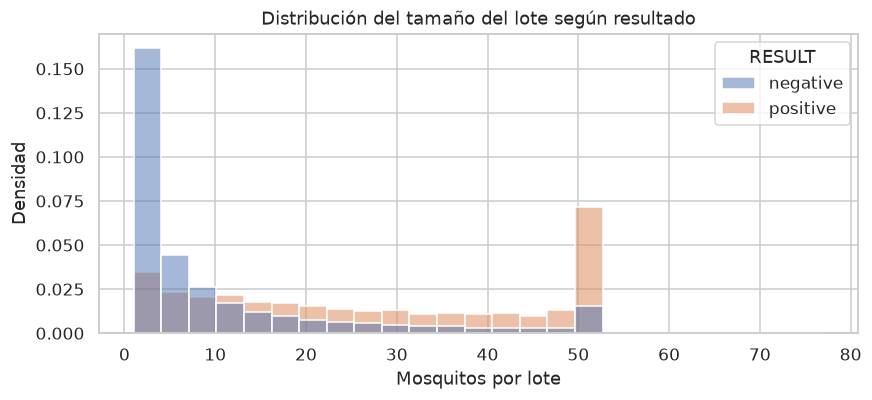

In [24]:
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(data=lotes, x='NUMBER OF MOSQUITOES', hue='RESULT', bins=25, stat='density', common_norm=False, ax=ax)
ax.set_xlabel('Mosquitos por lote')
ax.set_ylabel('Densidad')
ax.set_title('Distribución del tamaño del lote según resultado')
plt.tight_layout()
plt.show()

### Cómo leer las medidas y los gráficos

| Término | Qué significa |
|---|---|
| ρ de Spearman | Mide si dos variables suben juntas, de −1 a 1. Con 0 no hay relación, con 0,3 la relación es débil, con 0,6 clara y con 0,8 fuerte. Si es negativa, cuando una sube la otra baja |
| Faceted plot | El mismo gráfico repetido en paneles, uno por grupo (año, especie, zona), con los mismos ejes para compararlos a simple vista |
| Heatmap | Tabla en la que cada celda se colorea según su valor. Los colores más oscuros son los valores más altos |
| Cuadrantes | Se divide un gráfico de dos métricas con sus medianas, lo que deja cuatro grupos (alto-alto, alto-bajo, etc.) |
| Clasificación ABC (Pareto) | Se ordenan los distritos de más a menos positivos. La clase A son los que juntos suman el 80 % de los positivos |

## 8. Respuesta a las preguntas de negocio

### P1. ¿Qué porcentaje de distritos concentra la mayoría de lotes positivos? (clasificación ABC, Pareto 80/15/5)

,distritos,positivos,% distritos,% positivos
CLASE,,,,
A,18,3025,40.0,79.6
B,11,568,24.4,14.9
C,16,207,35.6,5.4


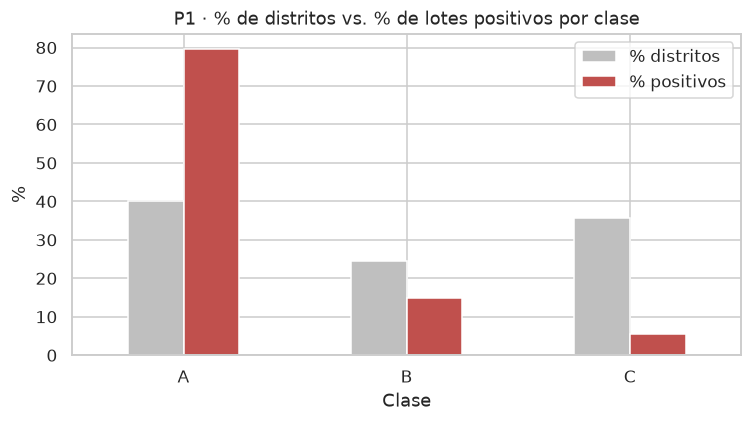

In [25]:
distritos = lotes.groupby('WARD')['POSITIVO'].sum().sort_values(ascending=False).to_frame('positivos')
distritos['acum_%'] = distritos['positivos'].cumsum() / distritos['positivos'].sum() * 100
distritos['CLASE'] = np.where(distritos['acum_%'] <= 80, 'A', np.where(distritos['acum_%'] <= 95, 'B', 'C'))
resumen_abc = distritos.groupby('CLASE').agg(distritos=('positivos','size'), positivos=('positivos','sum'))
resumen_abc['% distritos'] = (resumen_abc['distritos'] / len(distritos) * 100).round(1)
resumen_abc['% positivos'] = (resumen_abc['positivos'] / distritos['positivos'].sum() * 100).round(1)
display(resumen_abc)

fig, ax = plt.subplots(figsize=(7, 4))
resumen_abc[['% distritos', '% positivos']].plot(kind='bar', ax=ax, color=['#bfbfbf', '#c0504d'], rot=0)
ax.set_xlabel('Clase')
ax.set_ylabel('%')
ax.set_title('P1 · % de distritos vs. % de lotes positivos por clase')
plt.tight_layout()
plt.show()


**Interpretación P1:** el 40 % de los distritos (18, clase A) concentra el 79,6 % de los lotes positivos, y el 35,6 % (clase C) apenas el 5,4 %. El presupuesto de fumigación debería enfocarse en los distritos de la clase A.

### P2. ¿En qué semanas se concentra la infección y el pico se desplaza entre años?
Se grafica la MIR promedio de cada semana (todos los años juntos) y se busca la semana pico de cada año. Solo se usan semanas con al menos 100 mosquitos analizados.

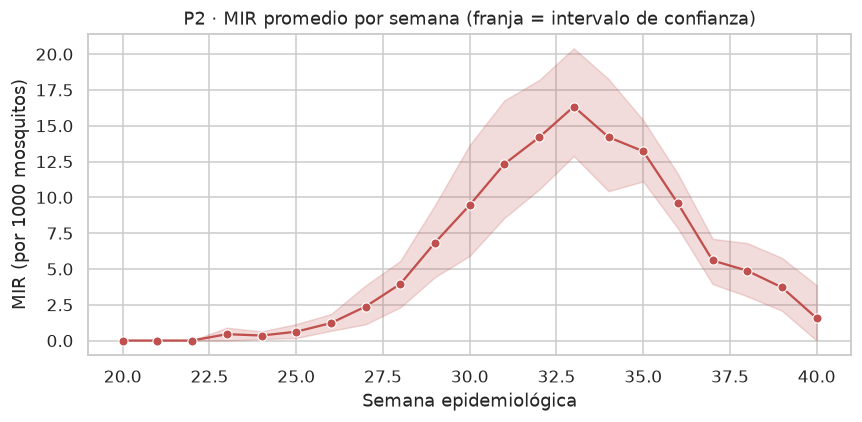

In [26]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.lineplot(data=semanas_validas, x='WEEK', y='MIR', marker='o', color='#c0504d', ax=ax)
ax.set_xlabel('Semana epidemiológica')
ax.set_ylabel('MIR (por 1000 mosquitos)')
ax.set_title('P2 · MIR promedio por semana (franja = intervalo de confianza)')
plt.tight_layout()
plt.show()


In [27]:
semana_pico_por_año = semanas_validas.loc[semanas_validas.groupby('AÑO')['MIR'].idxmax(), ['AÑO','WEEK','MIR']].rename(columns={'WEEK':'semana_pico'})
display(semana_pico_por_año.set_index('AÑO').round(1).T)
print(f"Semana pico mediana: {semana_pico_por_año['semana_pico'].median():.0f} | rango: {semana_pico_por_año['semana_pico'].min()} a {semana_pico_por_año['semana_pico'].max()}")


AÑO,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
semana_pico,35.0,36.0,33.0,33.0,32.0,30.0,34.0,36.0,33.0,31.0,34.0,34.0,35.0,34.0,34.0,32.0,33.0,30.0,33.0,31.0
MIR,24.0,10.7,11.7,18.8,13.3,22.5,14.5,16.8,19.3,23.4,26.0,40.3,20.3,11.5,19.3,22.5,24.1,21.3,42.1,28.3


Semana pico mediana: 33 | rango: 30 a 36


**Interpretación P2:** la infección se concentra entre las semanas 30 y 36, de fines de julio a inicios de septiembre. La curva promedio sube desde la semana 27 y llega al máximo en la 33. La semana pico mediana de los años también es la 33 y en 20 años el pico nunca salió de ese rango. Lo que cambió es la intensidad: los dos picos más altos fueron 42 por 1000 en 2025 y 40 en 2018, y desde 2023 todos los años superan 21 por 1000. Conviene que la fumigación preventiva y la eliminación de criaderos ya estén en marcha antes de la semana 30.

### P3. ¿Qué especie aporta más mosquitos y cuál se infecta más?
Se compara la abundancia vectorial y la MIR de las tres especies principales.

In [28]:
por_especie = lotes.groupby('ESPECIE').apply(resumen_infeccion).sort_values('mosquitos', ascending=False)
por_especie['ABUNDANCIA'] = por_especie['mosquitos'] / len(trampa_semanas_unicas)
display(por_especie.round(3))

,lotes,positivos,mosquitos,MIR,ABUNDANCIA
ESPECIE,,,,,
Cx. Pipiens/Restuans,17320.0,1985.0,266989.0,7.435,9.831
Cx. Restuans,13411.0,1204.0,146693.0,8.208,5.401
Cx. Pipiens,6145.0,603.0,53265.0,11.321,1.961
Cx. Territans,989.0,4.0,1935.0,2.067,0.071
Otras,360.0,4.0,688.0,5.814,0.025


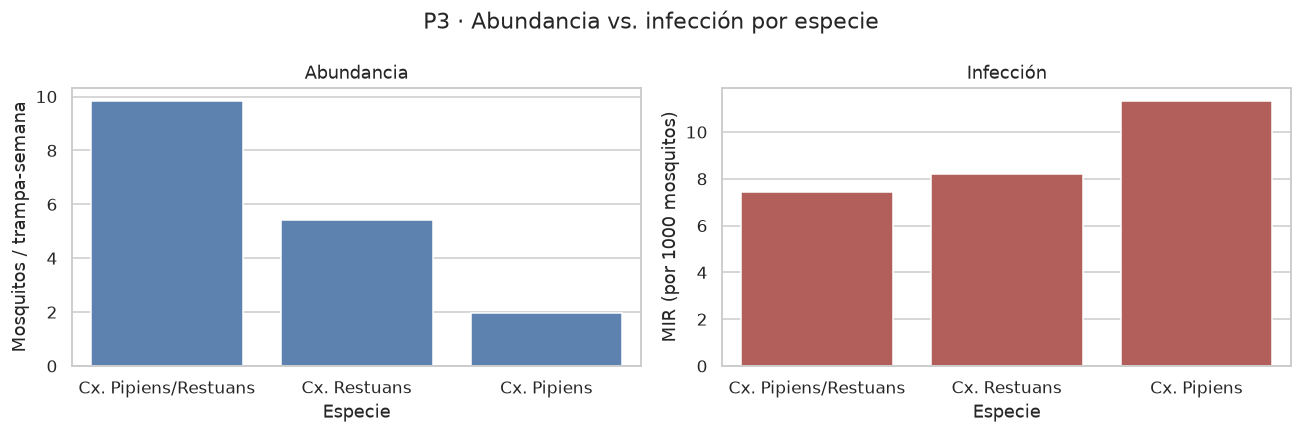

In [29]:
# especies principales: las 3 con más mosquitos que tienen al menos un positivo
principales = por_especie[por_especie['positivos'] > 0].head(3)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=principales.index, y=principales['ABUNDANCIA'], ax=ax[0], color='#4f81bd')
sns.barplot(x=principales.index, y=principales['MIR'], ax=ax[1], color='#c0504d')
ax[0].set_xlabel('Especie')
ax[0].set_ylabel('Mosquitos / trampa-semana')
ax[0].set_title('Abundancia')
ax[1].set_xlabel('Especie')
ax[1].set_ylabel('MIR (por 1000 mosquitos)')
ax[1].set_title('Infección')
fig.suptitle('P3 · Abundancia vs. infección por especie')
plt.tight_layout()
plt.show()


**Interpretación P3:** la especie más infectada no es la más abundante. *Cx. pipiens* tiene la MIR más alta (11,3 por 1000) y la abundancia más baja de las tres principales (2,0 mosquitos por trampa-semana). Los lotes mixtos *pipiens/restuans* aportan la mayor cantidad de mosquitos (9,8 por trampa-semana) con una MIR de 7,4. *Cx. territans* casi no se infecta (2,1). *Cx. restuans* queda en medio en ambas métricas (5,4 mosquitos por trampa-semana y MIR de 8,2), así que también participa en la transmisión.

### P4. ¿Los picos de abundancia y de infección ocurren en las mismas semanas?
El CDC (2013) advierte que los brotes suelen ocurrir cuando la abundancia ya bajó pero la infección es alta. Se grafican ambas curvas promedio por semana (cada una dividida por su máximo para verlas juntas) y se compara la semana pico de cada una en cada año.

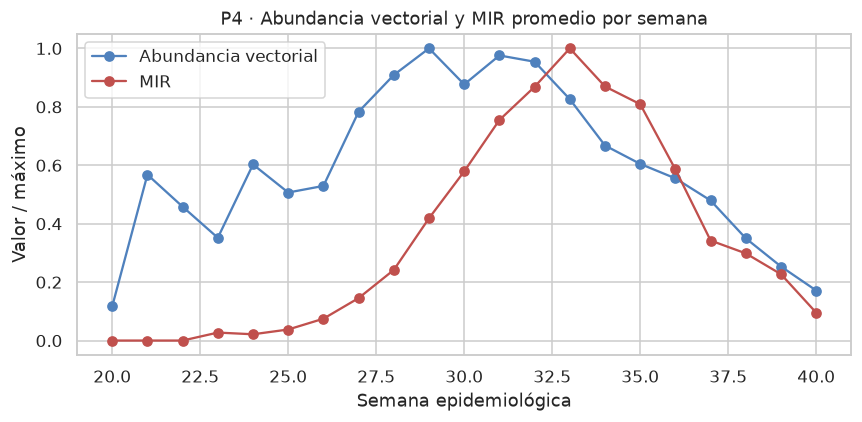

In [30]:
promedio_semana = semanas_validas.groupby('WEEK')[['ABUNDANCIA', 'MIR']].mean()
relativas = promedio_semana / promedio_semana.max()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(relativas.index, relativas['ABUNDANCIA'], marker='o', color='#4f81bd', label='Abundancia vectorial')
ax.plot(relativas.index, relativas['MIR'], marker='o', color='#c0504d', label='MIR')
ax.set_xlabel('Semana epidemiológica')
ax.set_ylabel('Valor / máximo')
ax.set_title('P4 · Abundancia vectorial y MIR promedio por semana')
ax.legend()
plt.tight_layout()
plt.show()


In [31]:
picos = semanas_validas.groupby('AÑO').apply(lambda grupo: pd.Series({
    'pico_abundancia': grupo.loc[grupo['ABUNDANCIA'].idxmax(), 'WEEK'],
    'pico_MIR': grupo.loc[grupo['MIR'].idxmax(), 'WEEK']}))
picos['desfase_semanas'] = picos['pico_MIR'] - picos['pico_abundancia']
print(f"Desfase mediano (pico MIR − pico abundancia): {picos['desfase_semanas'].median():.0f} semanas | "
      f"años con el pico de MIR después del de abundancia: {(picos['desfase_semanas'] > 0).sum()} de {len(picos)}")
rho = semanas_validas['ABUNDANCIA'].corr(semanas_validas['MIR'], method='spearman')
print(f'Spearman abundancia vs. MIR en la misma semana: rho = {rho:.3f}')


Desfase mediano (pico MIR − pico abundancia): 3 semanas | años con el pico de MIR después del de abundancia: 19 de 20
Spearman abundancia vs. MIR en la misma semana: rho = 0.256


**Interpretación P4:** en la curva promedio la abundancia llega al máximo hacia la semana 29 y la MIR en la 33. Año por año pasa lo mismo: en 19 de los 20 años el pico de la MIR llegó después del pico de abundancia, con un desfase mediano de 3 semanas. En la misma semana, abundancia e infección apenas se correlacionan (ρ = 0,26). Coincide con lo que describe el CDC (2013): los brotes suelen darse cuando la abundancia ya bajó, la población de mosquitos es más vieja y la infección es alta. El pico de capturas sirve como aviso de que el pico de infección llegará unas 3 semanas después.

### P5. ¿Qué zonas de la ciudad tienen más infección?
Se calcula la MIR de cada zona en cada año (solo si hay al menos 200 mosquitos) y se compara la MIR mediana de cada zona.

,MIR mediana anual
ZONA,
Noroeste,8.81
Extremo suroeste,8.27
Extremo norte,8.03
Suroeste,7.26
Norte,6.96
Oeste,6.68
Sur,6.06
Extremo sureste,5.14


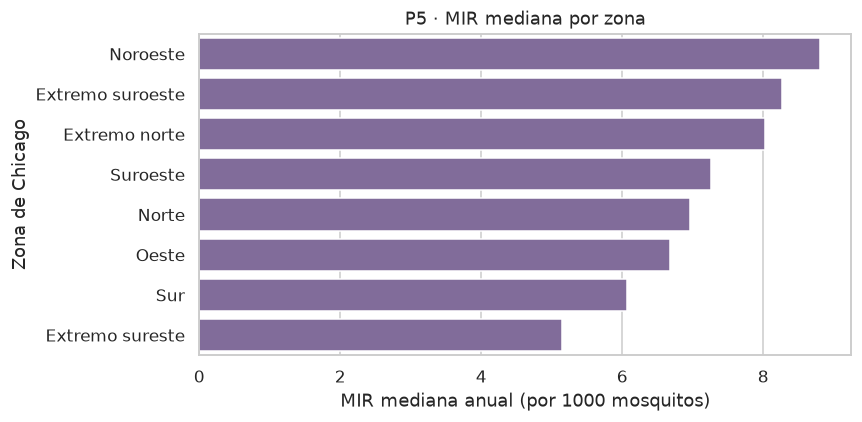

In [32]:
MIN_MOSQUITOS_CELDA = 200
zona_año = metricas(['AÑO', 'ZONA']).reset_index()
zona_año = zona_año[zona_año['mosquitos'] >= MIN_MOSQUITOS_CELDA]
mir_mediana_zona = zona_año.groupby('ZONA', observed=True)['MIR'].median().sort_values(ascending=False)
display(mir_mediana_zona.round(2).to_frame('MIR mediana anual'))

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=mir_mediana_zona.values, y=mir_mediana_zona.index.astype(str), color='#8064a2', ax=ax)
ax.set_xlabel('MIR mediana anual (por 1000 mosquitos)')
ax.set_ylabel('Zona de Chicago')
ax.set_title('P5 · MIR mediana por zona')
plt.tight_layout()
plt.show()


**Interpretación P5:** las diferencias entre zonas son moderadas. Las MIR anuales medianas más altas son las de Noroeste (8,8), Extremo suroeste (8,3) y Extremo norte (8,0), y la más baja la de Extremo sureste (5,1). La zona Centro no tiene suficientes mosquitos para calcular una MIR estable.

### P6. ¿Qué áreas comunitarias combinan mucha infección con muchos mosquitos?
Un área es prioritaria si tiene MIR alta (mosquitos muy infectados) y abundancia alta (muchos mosquitos). Se separan las áreas en cuadrantes con las medianas de ambas métricas. Solo entran áreas con al menos 100 trampa-semanas.

In [33]:
metricas_area = metricas(['COMMUNITY AREA NUMBER']).reset_index()
nombres_area = lotes.groupby('COMMUNITY AREA NUMBER')['COMMUNITY AREA NAME'].first()
metricas_area['AREA'] = metricas_area['COMMUNITY AREA NUMBER'].map(nombres_area)
metricas_area = metricas_area[metricas_area['trampa_semanas'] >= 100]

mediana_mir = metricas_area['MIR'].median()
mediana_abundancia = metricas_area['ABUNDANCIA'].median()
mir_alta = metricas_area['MIR'] >= mediana_mir
abundancia_alta = metricas_area['ABUNDANCIA'] >= mediana_abundancia

metricas_area['prioridad'] = np.select(
    [mir_alta & abundancia_alta, mir_alta, abundancia_alta],
    ['Alta: MIR y abundancia altas', 'MIR alta, pocos mosquitos', 'Muchos mosquitos, MIR baja'],
    default='Baja')
areas_mayor_mir = metricas_area.sort_values('MIR', ascending=False).head(15)
display(areas_mayor_mir[['AREA','MIR','ABUNDANCIA','trampa_semanas','positivos','prioridad']].round(2))
display(metricas_area['prioridad'].value_counts())

,AREA,MIR,ABUNDANCIA,trampa_semanas,positivos,prioridad
55,AUBURN GRESHAM,13.35,7.58,336,34.0,"MIR alta, pocos mosquitos"
10,NORTH PARK,13.28,19.98,294,78.0,Alta: MIR y abundancia altas
4,LAKE VIEW,11.95,4.94,322,19.0,"MIR alta, pocos mosquitos"
0,ROGERS PARK,11.69,2.61,361,11.0,"MIR alta, pocos mosquitos"
31,WOODLAWN,11.42,6.39,329,24.0,"MIR alta, pocos mosquitos"
50,WEST LAWN,11.20,21.73,296,72.0,Alta: MIR y abundancia altas
56,BEVERLY,10.92,11.41,714,89.0,"MIR alta, pocos mosquitos"
36,ROSELAND,10.63,7.48,390,31.0,"MIR alta, pocos mosquitos"
7,EDISON PARK,10.58,25.08,328,87.0,Alta: MIR y abundancia altas
33,CHATHAM,10.54,15.66,315,52.0,Alta: MIR y abundancia altas


prioridad
MIR alta, pocos mosquitos       14
Muchos mosquitos, MIR baja      14
Alta: MIR y abundancia altas    11
Baja                            10
Name: count, dtype: int64

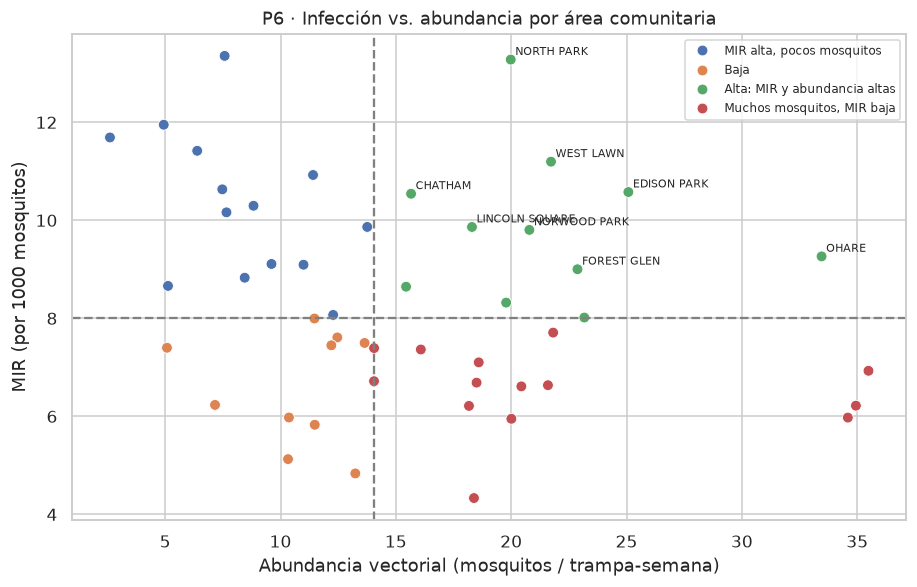

In [34]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.scatterplot(data=metricas_area, x='ABUNDANCIA', y='MIR', hue='prioridad', ax=ax, s=50)
ax.axvline(mediana_abundancia, ls='--', c='grey')
ax.axhline(mediana_mir, ls='--', c='grey')
for _, area in metricas_area[metricas_area['prioridad'].str.startswith('Alta')].nlargest(8, 'MIR').iterrows():
    ax.annotate(area['AREA'], (area['ABUNDANCIA'], area['MIR']), fontsize=7, xytext=(3,3), textcoords='offset points')
ax.set_xlabel('Abundancia vectorial (mosquitos / trampa-semana)')
ax.set_ylabel('MIR (por 1000 mosquitos)')
ax.set_title('P6 · Infección vs. abundancia por área comunitaria')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Interpretación P6:** 11 áreas tienen la MIR y la abundancia por encima de la mediana. Encabezan la lista North Park (MIR 13,3; 20 mosquitos por trampa-semana), West Lawn, Edison Park, Chatham, Lincoln Square y Norwood Park, además de O'Hare, que tiene la mayor abundancia (33,5). Son las áreas con prioridad de fumigación. Otras 14 áreas, como Auburn Gresham, Lake View y Rogers Park, tienen MIR alta pero pocos mosquitos; ahí basta con mantener la vigilancia.

### P7. ¿Los positivos acumulados hasta la semana 31 anticipan cuánto virus habrá en el resto de la temporada?
Karki et al. (2020) encontraron que los positivos acumulados a la semana 31 predicen los casos humanos del año en Chicago. Este dataset no tiene casos humanos, así que se compara lo acumulado hasta la semana 31 con los positivos que aparecen después de esa semana.

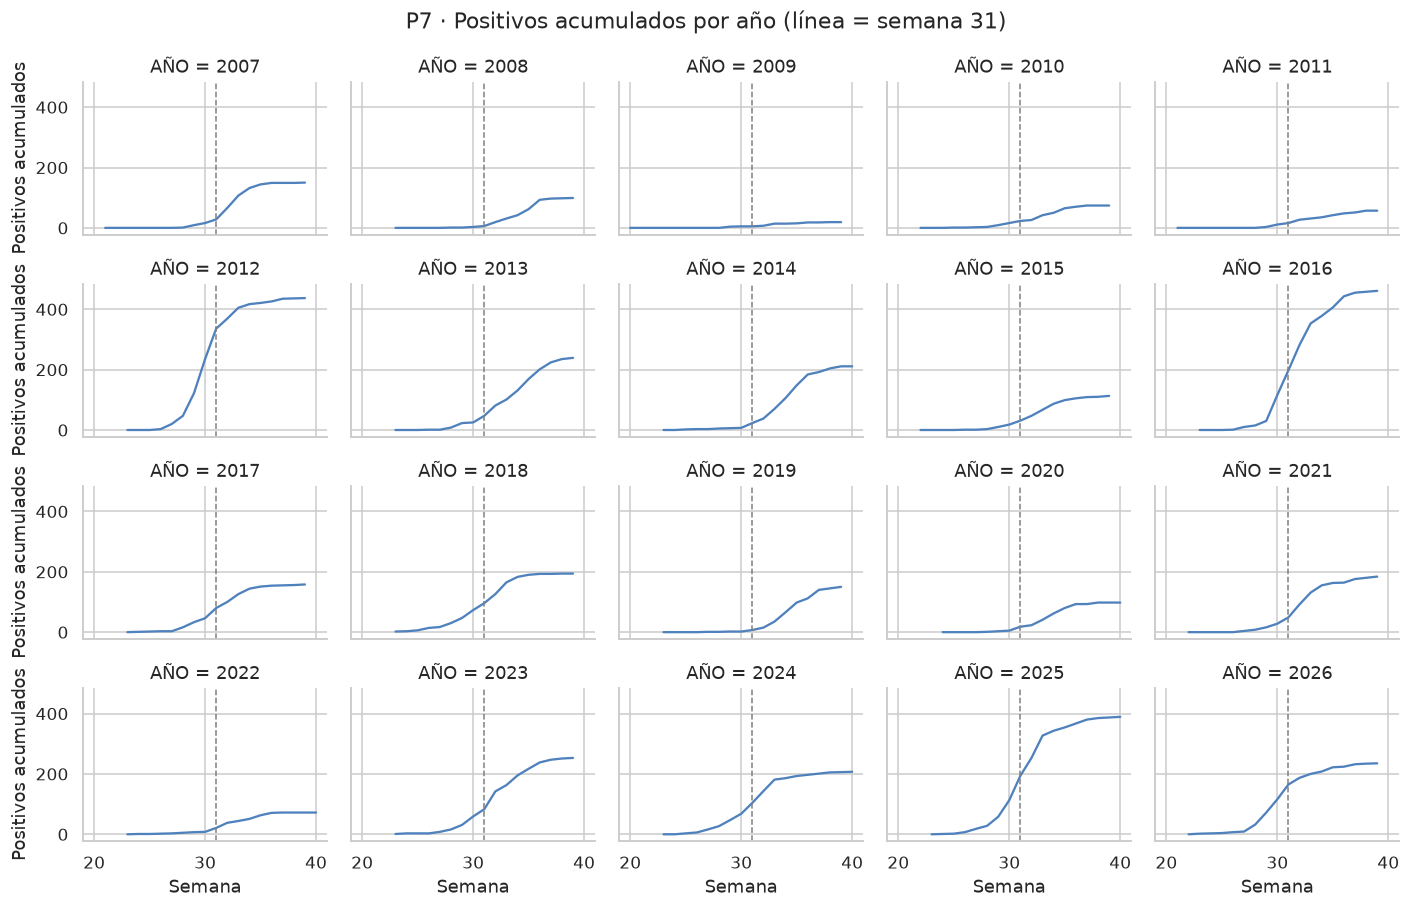

In [35]:
SEMANA_CORTE = 31   # Karki et al. (2020)
grafico = sns.relplot(data=metricas_semanales, x='WEEK', y='POS_ACUM', col='AÑO', col_wrap=5, kind='line',
                height=2.0, aspect=1.3, color='#4f81bd')
for ax in grafico.axes.flat:
    ax.axvline(SEMANA_CORTE, ls='--', color='grey', lw=1)
grafico.set_axis_labels('Semana', 'Positivos acumulados')
grafico.figure.suptitle('P7 · Positivos acumulados por año (línea = semana 31)', y=1.03)
plt.show()

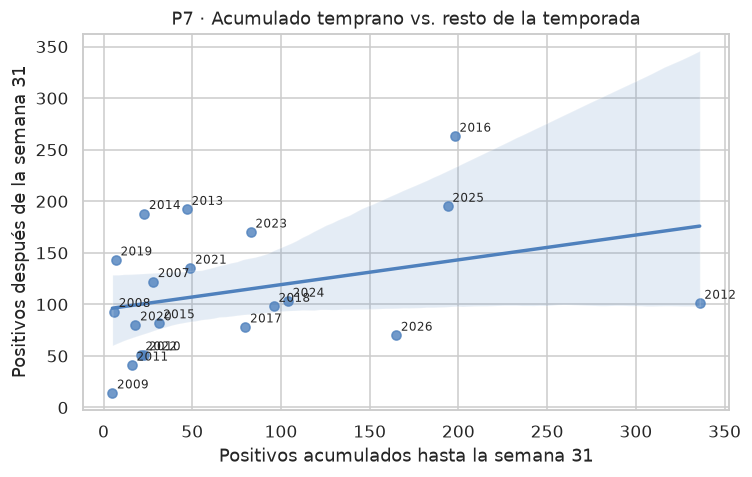

Spearman rho = 0.468
Proporción de los positivos del año que ya ocurrió a la semana 31 (mediana): 28.6 %


In [36]:
acum_31 = metricas_semanales[metricas_semanales['WEEK'] <= SEMANA_CORTE].groupby('AÑO')['POS_ACUM'].max()
despues_31 = metricas_semanales[metricas_semanales['WEEK'] > SEMANA_CORTE].groupby('AÑO')['positivos'].sum()
positivos_por_año = pd.DataFrame({'acum_31': acum_31, 'despues_31': despues_31}).fillna(0)

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.regplot(data=positivos_por_año, x='acum_31', y='despues_31', ax=ax, color='#4f81bd')
for año, fila in positivos_por_año.iterrows():
    ax.annotate(str(año), (fila['acum_31'], fila['despues_31']), fontsize=8, xytext=(3, 3), textcoords='offset points')
ax.set_xlabel('Positivos acumulados hasta la semana 31')
ax.set_ylabel('Positivos después de la semana 31')
ax.set_title('P7 · Acumulado temprano vs. resto de la temporada')
plt.tight_layout()
plt.show()

rho = positivos_por_año['acum_31'].corr(positivos_por_año['despues_31'], method='spearman')
proporcion_hasta_31 = positivos_por_año['acum_31'] / (positivos_por_año['acum_31'] + positivos_por_año['despues_31'])
print(f'Spearman rho = {rho:.3f}')
print(f'Proporción de los positivos del año que ya ocurrió a la semana 31 (mediana): {proporcion_hasta_31.median()*100:.1f} %')

**Interpretación P7:** a la semana 31 ya ocurrió, en mediana, el 29 % de los positivos del año. Ese acumulado anticipa lo que viene: los años con más positivos hasta la semana 31 tienen más positivos después (ρ = 0,47). En el faceted plot, 2012, 2016 y 2025 se separan del resto antes de la semana 31. Karki et al. (2020) usaron este mismo indicador para predecir casos humanos en Chicago. Si en la semana 31 el acumulado supera la mediana histórica (39 positivos), conviene reforzar el control para el resto de la temporada.

### P8. ¿La MIR de las semanas previas anticipa la infección de la semana actual?
Se correlaciona la MIR de cada semana con la MIR de 1 a 4 semanas antes (Karki et al., 2020). Parte de la correlación viene de la propia estacionalidad, así que también se mira dentro de cada fase de la temporada.

,rezago_semanas,rho
0,1,0.789
1,2,0.673
2,3,0.522
3,4,0.309


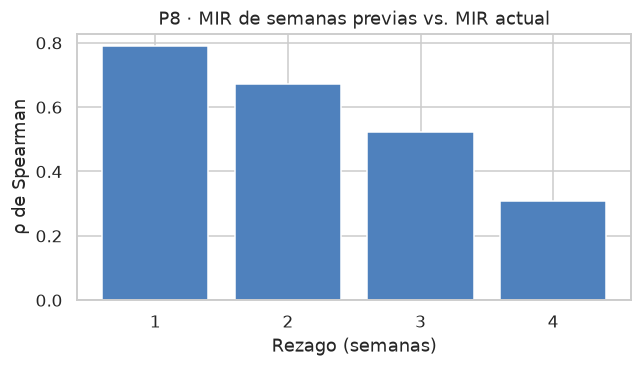

In [37]:
correl_previas = pd.DataFrame([
    {'rezago_semanas': rezago, 'rho': semanas_validas[f'MIR_PREV_{rezago}'].corr(semanas_validas['MIR'], method='spearman')}
    for rezago in REZAGOS])
display(correl_previas.style.format({'rho': '{:.3f}'}))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(correl_previas['rezago_semanas'], correl_previas['rho'], color='#4f81bd')
ax.set_xlabel('Rezago (semanas)')
ax.set_ylabel('ρ de Spearman')
ax.set_xticks(list(REZAGOS))
ax.set_title('P8 · MIR de semanas previas vs. MIR actual')
plt.tight_layout()
plt.show()

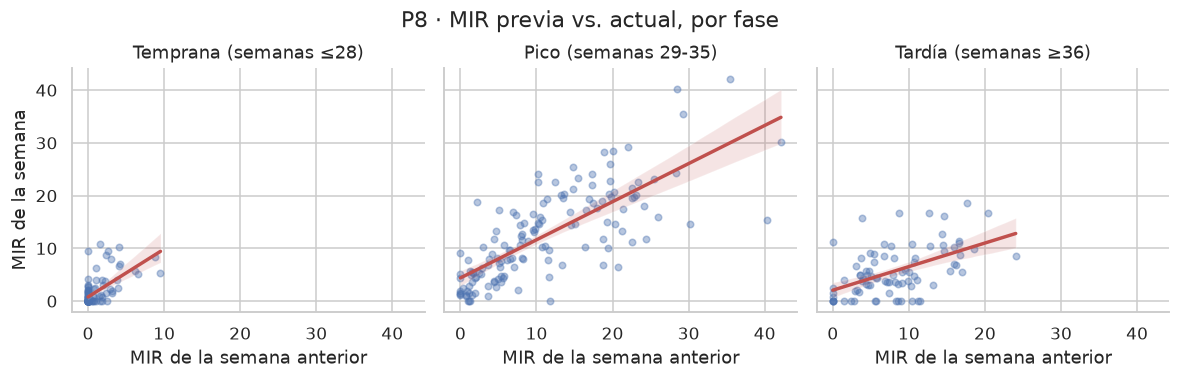

Temprana (semanas ≤28): rho = 0.591, n = 106
Pico (semanas 29-35): rho = 0.787, n = 140
Tardía (semanas ≥36): rho = 0.491, n = 84


In [38]:
semanas_con_mir_previa = semanas_validas.dropna(subset=['MIR_PREV_1'])

grafico = sns.lmplot(data=semanas_con_mir_previa, x='MIR_PREV_1', y='MIR', col='FASE',
                     height=3.3, aspect=1.1,
                     scatter_kws={'alpha': .4, 's': 18}, line_kws={'color': '#c0504d'})
grafico.set_axis_labels('MIR de la semana anterior', 'MIR de la semana')
grafico.set_titles('{col_name}')
grafico.figure.suptitle('P8 · MIR previa vs. actual, por fase', y=1.04)
plt.show()

for fase, semanas_de_la_fase in semanas_con_mir_previa.groupby('FASE', observed=True):
    rho = semanas_de_la_fase['MIR_PREV_1'].corr(semanas_de_la_fase['MIR'], method='spearman')
    print(f'{fase}: rho = {rho:.3f}, n = {len(semanas_de_la_fase)}')

**Interpretación P8:** la MIR de la semana anterior anticipa con fuerza la de la semana actual (ρ = 0,79). La relación se debilita con cada semana de rezago. 

### P9. ¿Con cuántas semanas de anticipación la temperatura y la lluvia se asocian con la infección?
Se correlaciona (Spearman) la MIR semanal con la temperatura y la lluvia de la misma semana y de 1 a 4 semanas antes, los mismos rezagos que usaron Karki et al. (2020). Solo se usan semanas con al menos 100 mosquitos.

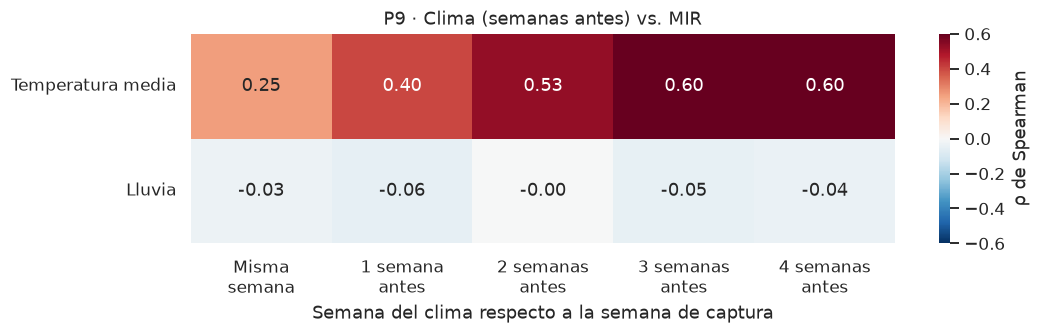

Mayor asociación de la temperatura: rezago de 4 semanas antes (ρ = 0.597)


In [39]:
NOMBRES_REZAGO = ['Misma\nsemana', '1 semana\nantes', '2 semanas\nantes', '3 semanas\nantes', '4 semanas\nantes']
correlaciones = {}
for base, prefijo, nombre in [('TAVG_SEM', 'TEMP_PREV', 'Temperatura media'), ('PRCP_SEM', 'LLUVIA_PREV', 'Lluvia')]:
    fila = {}
    for rezago in range(0, 5):
        col = base if rezago == 0 else f'{prefijo}_{rezago}'
        rho = semanas_validas[col].corr(semanas_validas['MIR'], method='spearman')
        fila[NOMBRES_REZAGO[rezago]] = rho
    correlaciones[nombre] = fila
tabla_rezagos = pd.DataFrame(correlaciones).T
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.grid(False)
sns.heatmap(tabla_rezagos, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-.6, vmax=.6, ax=ax, cbar_kws={'label':'ρ de Spearman'})
ax.set_xlabel('Semana del clima respecto a la semana de captura')
ax.set_ylabel('')
ax.tick_params(axis='both', rotation=0)
ax.set_title('P9 · Clima (semanas antes) vs. MIR')
plt.tight_layout()
plt.show()
mejor_temp = tabla_rezagos.loc['Temperatura media'].idxmax().replace('\n', ' ')
print(f"Mayor asociación de la temperatura: rezago de {mejor_temp} (ρ = {tabla_rezagos.loc['Temperatura media'].max():.3f})")

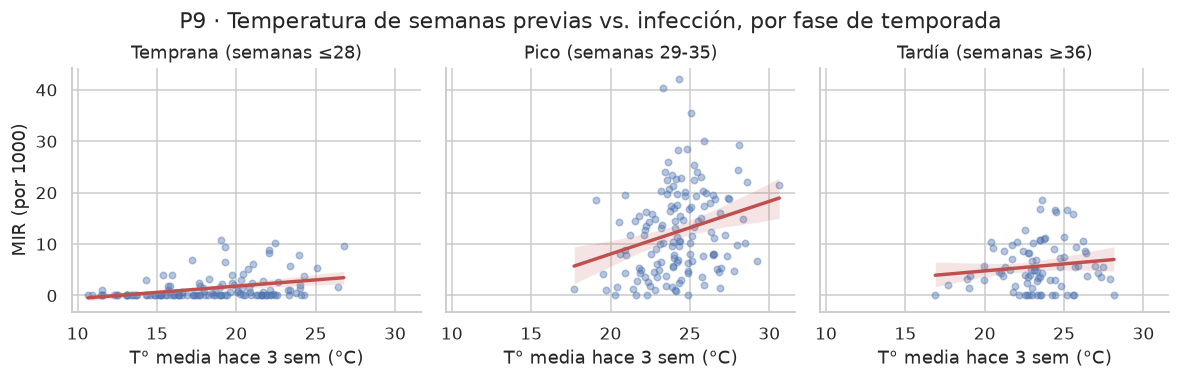

Temprana (semanas ≤28): rho = 0.344, n = 124
Pico (semanas 29-35): rho = 0.301, n = 140
Tardía (semanas ≥36): rho = 0.293, n = 84


In [40]:
grafico = sns.lmplot(data=semanas_validas, x='TEMP_PREV_4', y='MIR', col='FASE',
                     height=3.3, aspect=1.1,
                     scatter_kws={'alpha': .4, 's': 18}, line_kws={'color': '#c0504d'})
grafico.set_axis_labels('T° media hace 3 sem (°C)', 'MIR (por 1000)')
grafico.set_titles('{col_name}')
grafico.figure.suptitle('P9 · Temperatura de semanas previas vs. infección, por fase de temporada', y=1.04)
plt.show()

for fase, semanas_de_la_fase in semanas_validas.groupby('FASE', observed=True):
    rho = semanas_de_la_fase['TEMP_PREV_3'].corr(semanas_de_la_fase['MIR'], method='spearman')
    print(f'{fase}: rho = {rho:.3f}, n = {len(semanas_de_la_fase)}')

**Interpretación P9:** la temperatura es la variable climática que más se asocia con la infección, y su efecto llega con retraso. La correlación sube de ρ = 0,25 en la misma semana a cerca de 0,60 con 3 o 4 semanas de rezago. La lluvia casi no se relaciona con la MIR en ningún rezago (|ρ| ≤ 0,06 en todos). 

### P10. ¿Un enero más cálido anticipa una temporada más intensa?
Karki et al. (2020) usaron la temperatura media de enero como indicador del invierno y encontraron que un enero más cálido aumenta la probabilidad de casos humanos. Se compara `TEMP_ENERO` con la MIR anual y con los positivos acumulados a la semana 31.

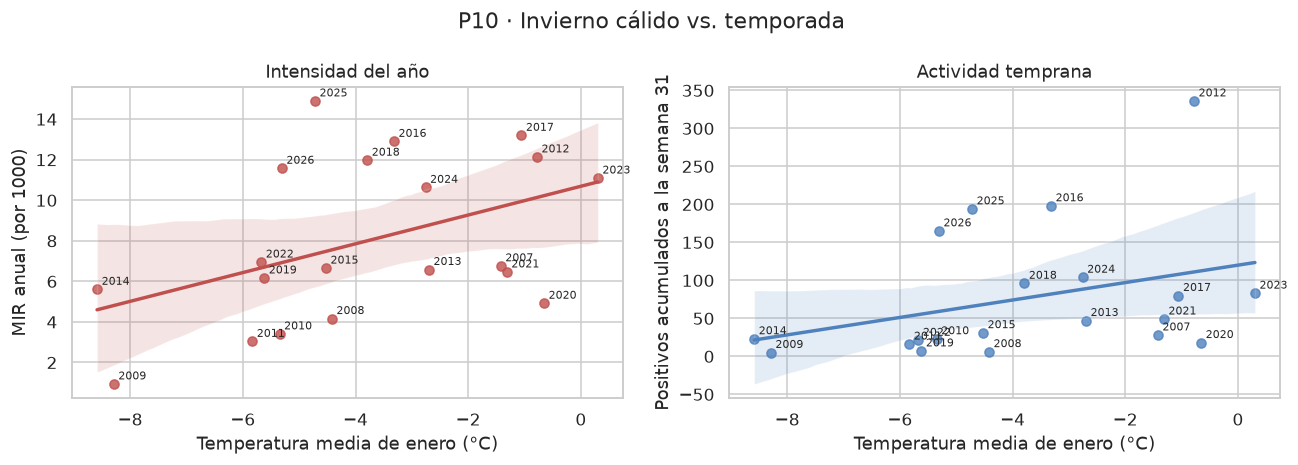

Enero vs MIR anual: ρ = 0.435
Enero vs positivos a la semana 31: ρ = 0.469


,MIR,TEMP_ENERO,acum_31
AÑO,,,
2014,5.60,-8.59,23.0
2009,0.94,-8.29,5.0
2011,3.03,-5.83,16.0
2022,6.95,-5.67,21.0
2019,6.16,-5.62,7.0
2010,3.40,-5.35,23.0
2026,11.57,-5.31,165.0
2025,14.89,-4.72,194.0
2015,6.65,-4.53,31.0


In [41]:
anual_enero = anual[['MIR', 'TEMP_ENERO']].join(acum_31.rename('acum_31')).dropna()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
sns.regplot(data=anual_enero, x='TEMP_ENERO', y='MIR', ax=ax[0], color='#c0504d')
sns.regplot(data=anual_enero, x='TEMP_ENERO', y='acum_31', ax=ax[1], color='#4f81bd')
for año, fila in anual_enero.iterrows():
    ax[0].annotate(str(año), (fila['TEMP_ENERO'], fila['MIR']), fontsize=7, xytext=(3,3), textcoords='offset points')
    ax[1].annotate(str(año), (fila['TEMP_ENERO'], fila['acum_31']), fontsize=7, xytext=(3,3), textcoords='offset points')
ax[0].set_xlabel('Temperatura media de enero (°C)')
ax[0].set_ylabel('MIR anual (por 1000)')
ax[0].set_title('Intensidad del año')
ax[1].set_xlabel('Temperatura media de enero (°C)')
ax[1].set_ylabel('Positivos acumulados a la semana 31')
ax[1].set_title('Actividad temprana')
fig.suptitle('P10 · Invierno cálido vs. temporada')
plt.tight_layout()
plt.show()

for variable, nombre in [('MIR','MIR anual'), ('acum_31','positivos a la semana 31')]:
    rho = anual_enero['TEMP_ENERO'].corr(anual_enero[variable], method='spearman')
    print(f'Enero vs {nombre}: ρ = {rho:.3f}')
display(anual_enero.sort_values('TEMP_ENERO').round(2))

**Interpretación P10:** los años con enero más cálido acumulan más positivos hasta la semana 31 (ρ = 0,47). Con la MIR anual la relación va en la misma dirección pero es algo más débil (ρ = 0,44).

## 9. Matriz de correlación de métricas semanales

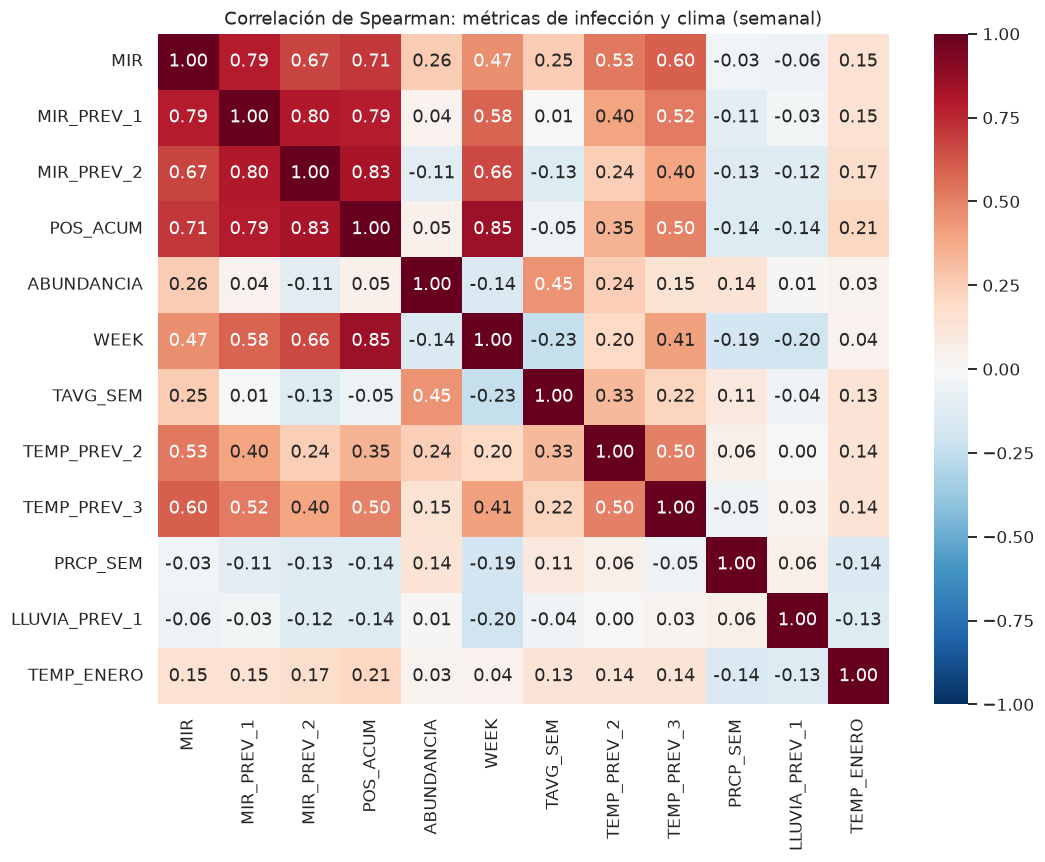

In [42]:
columnas_correlacion = ['MIR','MIR_PREV_1','MIR_PREV_2','POS_ACUM','ABUNDANCIA','WEEK','TAVG_SEM','TEMP_PREV_2','TEMP_PREV_3',
        'PRCP_SEM','LLUVIA_PREV_1','TEMP_ENERO']
matriz_correlacion = semanas_validas[columnas_correlacion].corr(method='spearman')
fig, ax = plt.subplots(figsize=(10, 8))
ax.grid(False)
sns.heatmap(matriz_correlacion, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlación de Spearman: métricas de infección y clima (semanal)')
plt.tight_layout()
plt.show()

## 10. Exportar datasets procesados

In [43]:
lotes.to_csv(RUTA_LIMPIO, index=False)
metricas_semanales.to_csv('wnv_metricas_semanales.csv', index=False)
clima_semanal.to_csv('clima_semanal.csv', index=False)
metricas_area.to_csv('wnv_metricas_area.csv', index=False)
print('Exportados:', RUTA_LIMPIO, 'wnv_metricas_semanales.csv', 'wnv_metricas_area.csv', 'clima_semanal.csv')
if EN_COLAB:
    for archivo in [RUTA_LIMPIO, 'wnv_metricas_semanales.csv', 'wnv_metricas_area.csv', 'clima_semanal.csv']:
        files.download(archivo)

Exportados: wnv_limpio.csv wnv_metricas_semanales.csv wnv_metricas_area.csv clima_semanal.csv


## 11. Conclusiones

1. Calidad de datos: el dataset tiene un 15,95 % de ruido, sobre todo trampas sin captura (11,8 %) y trampas no GRAVID (3,3 %). Las trampas sin captura no sirven para medir infección, pero entran como trampa-semanas con 0 mosquitos en la abundancia vectorial. Las columnas de latitud y longitud venían intercambiadas y se corrigieron.
2. Estacionalidad: la infección se concentra entre las semanas 30 y 36, con pico mediano en la 33. Desde 2023 los picos son más altos.
3. Alerta temprana: la MIR de la semana anterior anticipa la de la semana actual (ρ = 0,79). El pico de abundancia llega unas 3 semanas antes que el de infección, y los positivos acumulados a la semana 31 anticipan el resto de la temporada (ρ = 0,47).
4. Vectores: *Cx. pipiens* es la especie más infectada (MIR = 11,3 por 1000) y los lotes mixtos *pipiens/restuans* aportan la mayor abundancia.
5. Geografía: el riesgo es mayor en el norte de la ciudad (Noroeste y Extremo norte), junto con Extremo suroeste. Hay 11 áreas con MIR y abundancia altas a la vez, que son la prioridad de fumigación.
6. Recursos: el 40 % de los distritos concentra el 80 % de los positivos.
7. Clima (NOAA): la temperatura de 3 o 4 semanas antes es el principal factor climático (ρ ≈ 0,60). Un enero cálido se asocia con más actividad temprana (ρ = 0,47). La lluvia de semanas previas no mostró efecto.
8. Sistema de alerta propuesto: revisar la temperatura de enero al inicio del año; durante la temporada, seguir la temperatura de las 3 semanas previas, el pico de abundancia y la MIR de la semana anterior; y en la semana 31, comparar los positivos acumulados con la mediana histórica. En conjunto dan tiempo para fumigar antes del pico de infección.